In [1]:
from sklearn.metrics import mean_squared_error, mean_absolute_error

from scipy.stats import norm
from statsmodels.graphics.gofplots import qqplot
from statsmodels.graphics.tsaplots import plot_acf

from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.stattools import adfuller
from itertools import product

import random

from pathlib import Path
import sys
# Agregar el path del directorio "code"
code_path = Path("../code").resolve()
if str(code_path) not in sys.path:
    sys.path.insert(0, str(code_path))


import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from TimeSeriesLib import MeanRollingForecast, LastRollingForecast, SarimaxRollingForecast

import warnings
from statsmodels.tools.sm_exceptions import EstimationWarning

warnings.simplefilter('ignore', EstimationWarning)
warnings.simplefilter('ignore', UserWarning) # A veces statsmodels lanza warnings por convergencia

KeyboardInterrupt: 

In [ ]:
#TODO Pipeline que procese todo cammesa_data_x
df_a = pd.read_csv("../datasets/cammesa_data_A.csv",parse_dates=["fecha"])
df_b = pd.read_csv("../datasets/cammesa_data_B.csv",parse_dates=["fecha"])

df_combinado = pd.concat([df_a, df_b], ignore_index=True)

# 4. Eliminar duplicados basados ÚNICAMENTE en el campo 'fecha'
# 'keep="first"' conserva el primer registro encontrado (puedes usar 'keep="last"' si prefieres el de B)
df = df_combinado.drop_duplicates(subset=["fecha"], keep="first")

# 5. Ordenar por fecha para mantener la coherencia temporal
df = df.sort_values(by="fecha").reset_index(drop=True)

print(f"Filas originales A: {len(df_a)}, B: {len(df_b)}")
print(f"Filas combinadas sin duplicados: {len(df)}")



Filas originales A: 64159, B: 74293
Filas combinadas sin duplicados: 82967


Agrupamos diariamente

In [ ]:
df = df.iloc[:-1] #quito el dia ultimo por no tener datos

In [ ]:
df = df[["fecha", "demanda", "temp", "esDiaHabil"]]
df['fecha'] = pd.to_datetime(df['fecha']).dt.tz_localize(None)
#agrupemos
df = (
    df.groupby(df['fecha'].dt.to_period('D'))
    .agg({
        'demanda': 'mean',
        'temp': 'mean',
        'esDiaHabil': 'mean'  # En pandas, la media de un booleano calcula la proporción
    })
    .reset_index()
)

df['esDiaHabil'] = df['esDiaHabil'].astype(int)

In [ ]:
df["demanda"] = df["demanda"]/1000

No hay nulos. ¿Hay faltantes?

In [ ]:
lrange = pd.period_range(start=df['fecha'].min(), end=df['fecha'].max(), freq='D')
dtdiff = lrange.difference(df['fecha'])

# 3. Mostrar el resultado
if len(dtdiff) == 0:
    print("Ok fechas")
else:
    print("Hay faltantes")
    print(dtdiff)

Ok fechas


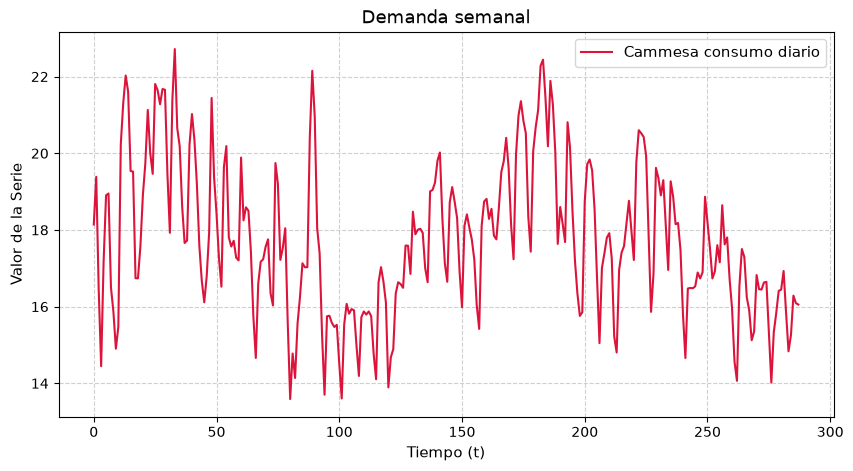

In [42]:
plt.figure(figsize=(10, 5))
plt.plot(df["demanda"], label=f'Cammesa consumo diario', color='crimson', linewidth=1.5)
plt.title('Demanda semanal', fontsize=13)
plt.xlabel('Tiempo (t)', fontsize=11)
plt.ylabel('Valor de la Serie', fontsize=11)
plt.legend(fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

¿Es estacionaria?

In [43]:
ADF_result = adfuller(df["demanda"], result_object=False) #result_object=False para silenciar warning de deprecado 2027
#print(f'ADF Statistic: {ADF_result[0]}')
print(f'p-value: {ADF_result[1]}')

p-value: 0.1780913440115779


p-value>0.05, diferenciemos.

In [44]:
df_diff = df.copy()
df_diff["diff"] = df['demanda'].diff()
df_diff = df_diff.dropna(subset=["diff"]).reset_index(drop=True)

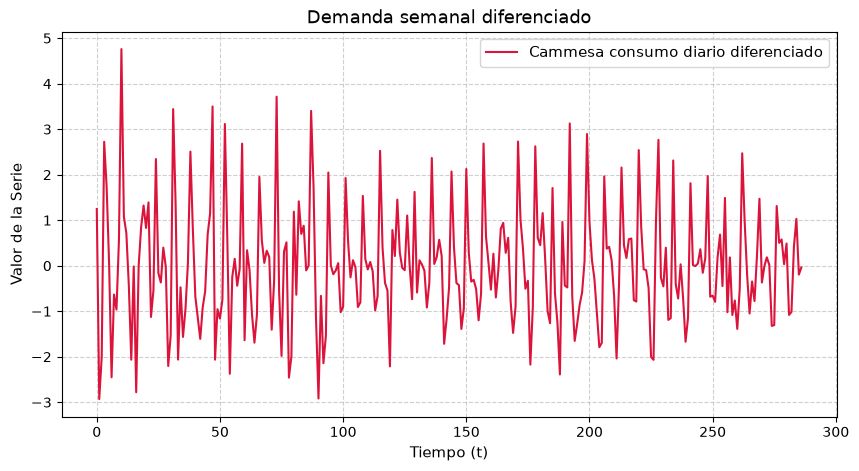

In [45]:
plt.figure(figsize=(10, 5))
plt.plot(df_diff["diff"], label=f'Cammesa consumo diario diferenciado', color='crimson', linewidth=1.5)
plt.title('Demanda semanal diferenciado', fontsize=13)
plt.xlabel('Tiempo (t)', fontsize=11)
plt.ylabel('Valor de la Serie', fontsize=11)
plt.legend(fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()


In [46]:
ADF_result = adfuller(df_diff["diff"], result_object=False) #result_object=False para silenciar warning de deprecado 2027
#print(f'ADF Statistic: {ADF_result[0]}')
print(f'p-value: {ADF_result[1]}')

p-value: 9.60745677345531e-07


Es estacionaria

¿Hay autocorrelacion, hay autocorrelacion parcial?

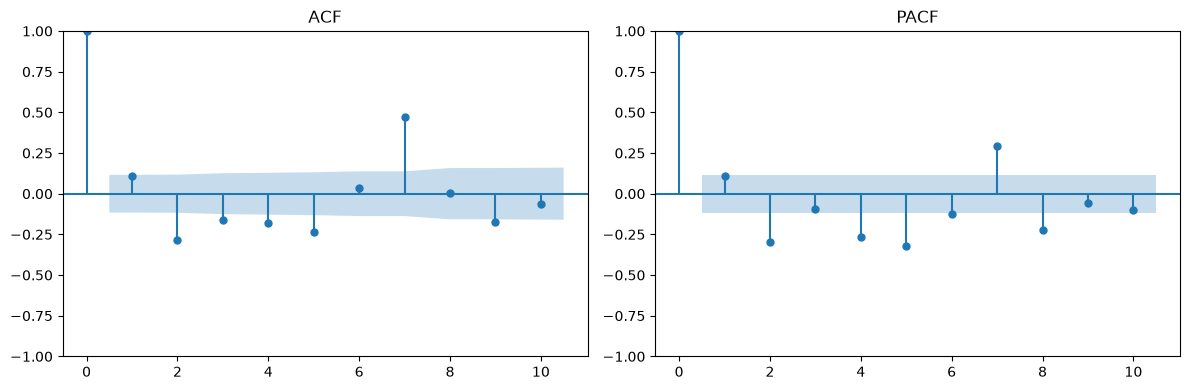

In [47]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# ACF
plot_acf(df_diff["diff"], ax=axes[0], lags=10, alpha=0.05)
axes[0].set_title("ACF")

# PACF
plot_pacf(df_diff["diff"], ax=axes[1], lags=10, alpha=0.05, method="ywm")
axes[1].set_title("PACF")

plt.tight_layout()
plt.show()

Nada claro...

¿Hay estacionalidad? (Serie original). Se que es de "7 dias", por ahora ignoro.

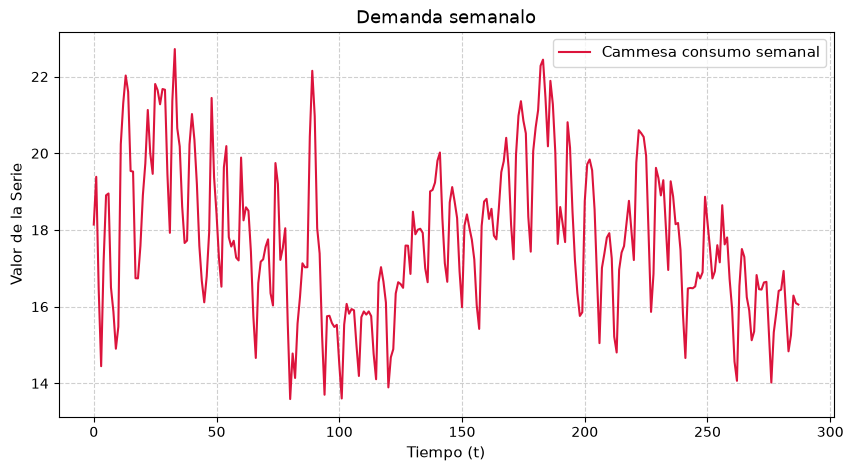

In [48]:
plt.figure(figsize=(10, 5))
plt.plot(df["demanda"], label=f'Cammesa consumo semanal', color='crimson', linewidth=1.5)
plt.title('Demanda semanalo', fontsize=13)
plt.xlabel('Tiempo (t)', fontsize=11)
plt.ylabel('Valor de la Serie', fontsize=11)
plt.legend(fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

Entonces no parece AR puro ni MA puro. Probemos alternativas

In [54]:
window  = 1 # Solo un paso adelante.
train_percent = 0.8

In [51]:
#Demora 13 minutos...

ps      = range(0, 8, 1)    
qs      = range(0, 8, 1)
d       = 1 #Esto ya se que es uno


order_list = list(product(ps, qs))

results = []
for p, q in order_list:
    try:
        model = SarimaxRollingForecast(window=window, train_percent=0.8, target_col="demanda", order=(p, d, q))
        model.fit(df[["demanda"]])
        model.predict(df[["demanda"]])
        
        aic = model.aic_
        results.append([(p, q), aic])
        
    except Exception as e:
        print(f"Error con la orden ({p}, {q}), omitiendo... {e}")
        continue

Error con la orden (5, 2), omitiendo... LU decomposition error.


Verifiquemos ganador

In [52]:
result_df = pd.DataFrame(results)
result_df.columns = ['(p,q)', 'AIC']
#Sort in ascending order, lower AIC is better
result_df = result_df.sort_values(by='AIC', ascending=True).reset_index(drop=True)
result_df.loc[:5,:]

,"(p,q)",AIC
0,"(7, 7)",779.087229
1,"(6, 5)",800.182533
2,"(7, 6)",803.380319
3,"(6, 7)",814.500669
4,"(6, 6)",816.760874
5,"(7, 5)",823.346740


7, 7 para mi que tiene algo que ver la cuestion semanal :)

Ahora los modelos ¿Puedo ganar?

In [55]:
estimators = {}
estimators["mean"]      = MeanRollingForecast(window=window, train_percent=train_percent, mean_steps=5)
estimators["last"]      = LastRollingForecast(window=window, train_percent=train_percent)
estimators["sarimax"]   = SarimaxRollingForecast(window=window, train_percent=train_percent, order=(7,1,7), target_col="demanda") #diferencia 1 segun analizamos

for k, v in estimators.items():
    v.fit(df[["demanda"]])
    y_pred = v.predict(df[["demanda"]])
    df[k] = y_pred


Determinamos window = 1

Mean: 1.40, Last: 0.89, MA: 0.43


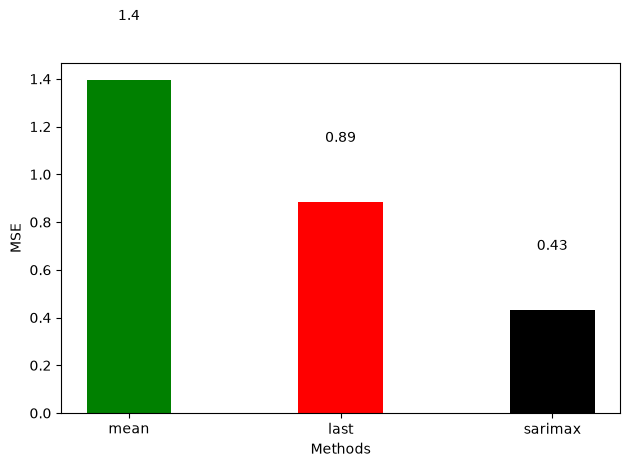

In [56]:
print("Mean: {:.2f}, Last: {:.2f}, MA: {:.2f}".format(estimators["mean"].score(), estimators["last"].score(), estimators["sarimax"].score()))
fig, ax = plt.subplots()
x = ['mean', 'last', 'sarimax']
y = [estimators["mean"].score(), estimators["last"].score(), estimators["sarimax"].score()]
ax.bar(x, y, width=0.4, color=['g', 'r', 'k'])
ax.set_xlabel('Methods')
ax.set_ylabel('MSE')
#ax.set_ylim(0, 5)
for index, value in enumerate(y):
    plt.text(x=index, y=value+0.25, s=str(round(value, 2)), ha='center')
plt.tight_layout()
plt.show()

Epa epa...hay un triunfo aca...

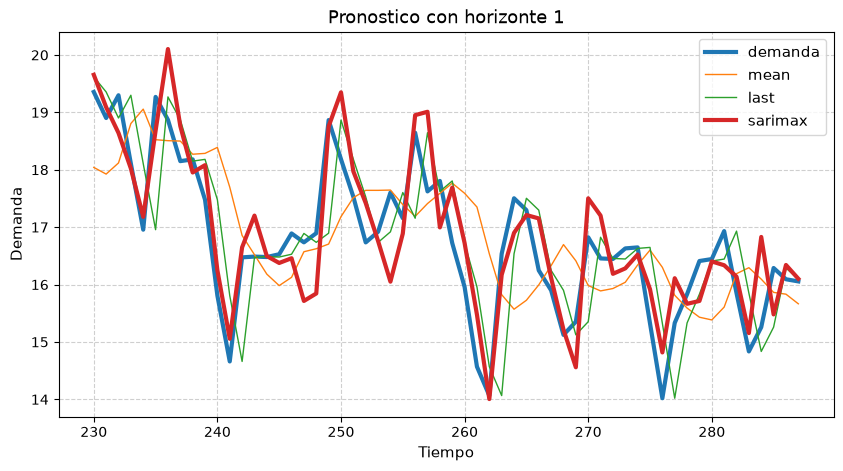

In [58]:
df_plot = df[["demanda", "mean", "last", "sarimax"]]

styles = {"demanda": {"linewidth":3}, 
          "mean": {"linewidth":1}, 
          "last": {"linewidth":1}, 
          "sarimax":{"linewidth":3}}

plt.figure(figsize=(10, 5))
for col in df_plot.columns:
    plt.plot(df_plot[y_pred.index[0]:].index, df_plot[y_pred.index[0]:][col], label=f'{col}', linewidth=styles[col]["linewidth"])

plt.title(f'Pronostico con horizonte {window}', fontsize=13)
plt.xlabel('Tiempo', fontsize=11)
plt.ylabel('Demanda', fontsize=11)
plt.legend(fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

¿Y los residuos?

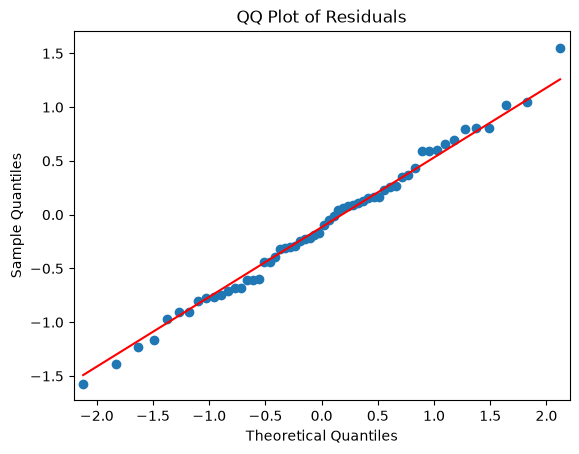

In [62]:
residuals = estimators["sarimax"].resid_
qqplot(residuals, line='s');
plt.title('QQ Plot of Residuals')
plt.show()


Los residuos parecen tener una distribucion normal, podriamos considerar una pronostico válido.

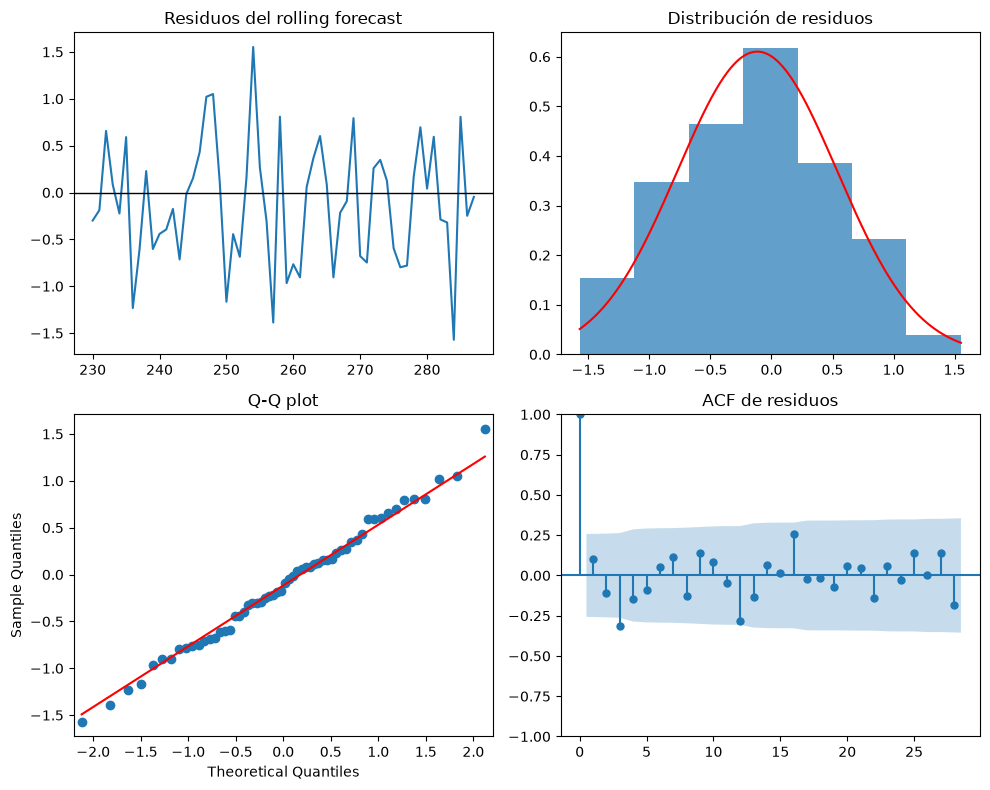

In [ ]:
residuals = estimators["sarimax"].resid_.dropna()
fig, axes = plt.subplots(2, 2, figsize=(10, 8))

# Residuos a lo largo del tiempo
axes[0, 0].plot(residuals.index, residuals)
axes[0, 0].axhline(0, color="black", linewidth=1)
axes[0, 0].set_title("Residuos del rolling forecast")

# Distribución de los residuos comparada con una normal
axes[0, 1].hist(residuals, bins="auto", density=True, alpha=0.7)
x = np.linspace(residuals.min(), residuals.max(), 200)
axes[0, 1].plot(x, norm.pdf(x, residuals.mean(), residuals.std()), color="red")
axes[0, 1].set_title("Distribución de residuos")

# Gráfico Q-Q
qqplot(residuals, line="s", ax=axes[1, 0])
axes[1, 0].set_title("Q-Q plot")

# Autocorrelación de los residuos
lags = min(40, len(residuals) // 2 - 1)
plot_acf(residuals, lags=lags, ax=axes[1, 1])
axes[1, 1].set_title("ACF de residuos")

plt.tight_layout()
plt.show()